# Lab Problem 8 : Exploring Polynomial Kernel Degree and Kernel Selection

Task 1: Dataset Preparation

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Fetch Iris records and isolate the first two columns (sepal length & width)
iris_data = load_iris()
sepal_raw = iris_data.data[:, :2]
species_idx = iris_data.target
species_names = iris_data.target_names

# Center and scale across all 150 observations
scaler = StandardScaler()
sepal_std = scaler.fit_transform(sepal_raw)

print(f"Standardized matrix shape : {sepal_std.shape}")
print(f"Column means (approx. 0)  : {np.round(sepal_std.mean(axis=0), 4)}")
print(f"Column stds  (approx. 1)  : {np.round(sepal_std.std(axis=0), 4)}")

Standardized matrix shape : (150, 2)
Column means (approx. 0)  : [-0. -0.]
Column stds  (approx. 1)  : [1. 1.]


Task 2: Implement Kernel Functions

In [8]:
def linear_kernel_matrix(mat_a: np.ndarray, mat_b: np.ndarray) -> np.ndarray:
    """Computes K_linear(x, z) = x^T z for all row pairs in mat_a and mat_b."""
    return mat_a @ mat_b.T


def poly_kernel_matrix(
    mat_a: np.ndarray,
    mat_b: np.ndarray,
    degree: int,
    gamma: float = 0.5,
    coef0: float = 1.0,
) -> np.ndarray:
    """Computes K_d(x, z) = (gamma * (x^T z) + coef0)^degree."""
    pairwise_dots = mat_a @ mat_b.T
    return np.power(gamma * pairwise_dots + coef0, degree)

Task 3: Kernel Matrix Computation

In [9]:
# Extract the first 8 standardized samples (all Iris-setosa)
sample_subset = sepal_std[:8]

# Bundle kernel configurations to avoid repetitive code blocks
kernel_configs = [
    ("Linear Kernel", linear_kernel_matrix(sample_subset, sample_subset)),
    ("Polynomial (Degree 2)", poly_kernel_matrix(sample_subset, sample_subset, degree=2)),
    ("Polynomial (Degree 3)", poly_kernel_matrix(sample_subset, sample_subset, degree=3)),
    ("Polynomial (Degree 5)", poly_kernel_matrix(sample_subset, sample_subset, degree=5)),
]

# Round entries to 2 decimal places and store for visualization
rounded_kernels = {}
np.set_printoptions(precision=2, suppress=True, linewidth=110)

for label, raw_matrix in kernel_configs:
    rounded_mat = np.round(raw_matrix, 2)
    rounded_kernels[label] = rounded_mat
    print(f"\n--- {label} (8x8) ---")
    print(rounded_mat)


--- Linear Kernel (8x8) ---
[[1.85 0.9  1.58 1.46 2.19 2.46 2.16 1.72]
 [0.9  1.32 1.54 1.71 1.   0.36 1.62 1.06]
 [1.58 1.54 2.03 2.12 1.83 1.38 2.35 1.67]
 [1.46 1.71 2.12 2.28 1.66 1.   2.35 1.62]
 [2.19 1.   1.83 1.66 2.6  2.97 2.52 2.03]
 [2.46 0.36 1.38 1.   2.97 4.05 2.34 2.08]
 [2.16 1.62 2.35 2.35 2.52 2.34 2.89 2.16]
 [1.72 1.06 1.67 1.62 2.03 2.08 2.16 1.67]]

--- Polynomial (Degree 2) (8x8) ---
[[3.7  2.1  3.21 2.99 4.4  4.97 4.33 3.47]
 [2.1  2.76 3.13 3.44 2.25 1.39 3.27 2.35]
 [3.21 3.13 4.05 4.24 3.66 2.86 4.72 3.38]
 [2.99 3.44 4.24 4.58 3.35 2.25 4.72 3.27]
 [4.4  2.25 3.66 3.35 5.3  6.18 5.12 4.06]
 [4.97 1.39 2.86 2.25 6.18 9.15 4.71 4.16]
 [4.33 3.27 4.72 4.72 5.12 4.71 5.98 4.33]
 [3.47 2.35 3.38 3.27 4.06 4.16 4.33 3.36]]

--- Polynomial (Degree 3) (8x8) ---
[[ 7.13  3.03  5.75  5.16  9.22 11.09  9.    6.46]
 [ 3.03  4.59  5.55  6.38  3.39  1.64  5.92  3.6 ]
 [ 5.75  5.55  8.16  8.74  7.    4.83 10.26  6.2 ]
 [ 5.16  6.38  8.74  9.8   6.14  3.37 10.27  5.91]
 [ 

Task 4: Kernel Matrix Visualization and Comparison

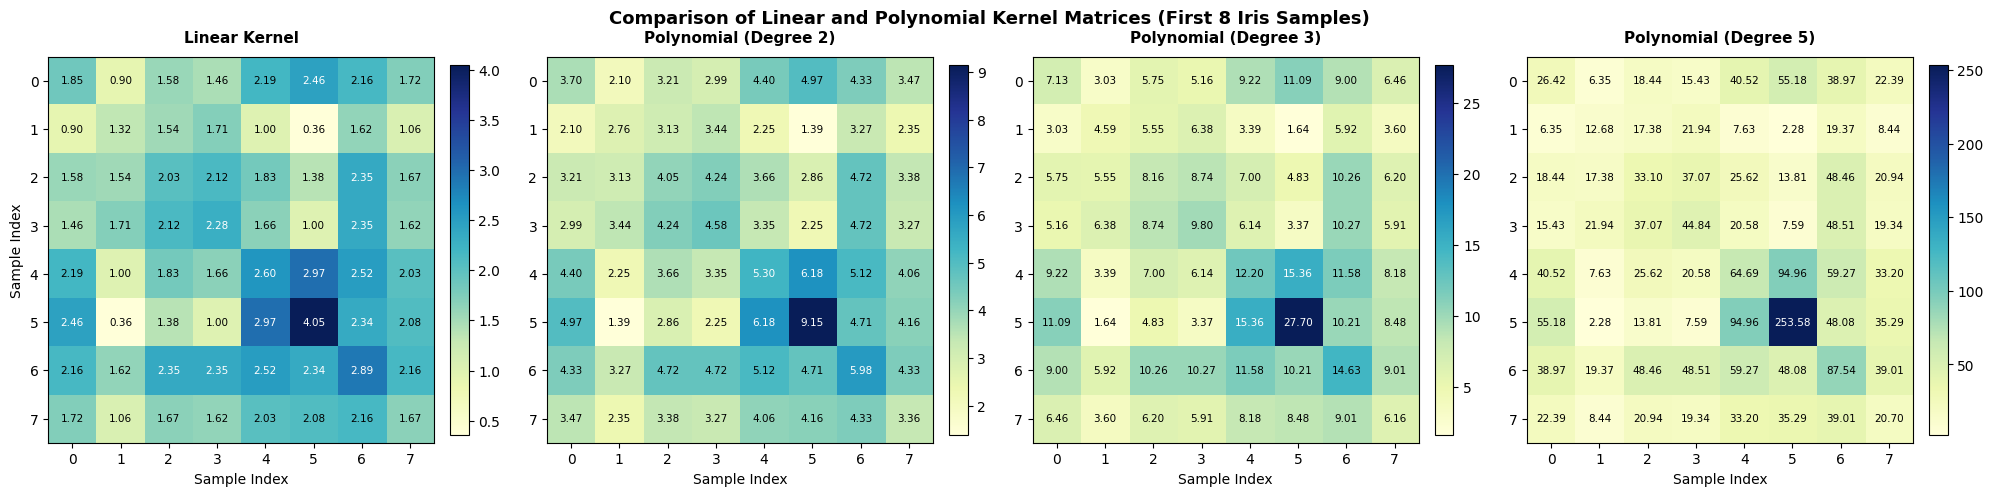

In [10]:
fig = plt.figure(figsize=(20, 4.8), constrained_layout=True)
grid = GridSpec(1, 4, figure=fig)

for idx, (title, k_mat) in enumerate(rounded_kernels.items()):
    ax = fig.add_subplot(grid[0, idx])
    heatmap = ax.imshow(k_mat, cmap="YlGnBu", aspect="equal")

    # Annotate cells with exact 2-decimal values for readability
    threshold = (k_mat.max() + k_mat.min()) / 2.0
    for r_idx in range(k_mat.shape[0]):
        for c_idx in range(k_mat.shape[1]):
            text_color = "white" if k_mat[r_idx, c_idx] > threshold else "black"
            ax.text(
                c_idx, r_idx, f"{k_mat[r_idx, c_idx]:.2f}",
                ha="center", va="center", color=text_color, fontsize=7.5
            )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xlabel("Sample Index")
    if idx == 0:
        ax.set_ylabel("Sample Index")
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))

    # Attach an individual colorbar to each subplot
    fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Comparison of Linear and Polynomial Kernel Matrices (First 8 Iris Samples)", fontsize=13, fontweight="bold")
plt.show()

Task 5: Nonlinear Feature Transformation

In [11]:
def map_to_6d_space(features_2d: np.ndarray) -> np.ndarray:
    """Maps 2D points (x1, x2) into the 6D feature space induced by K_2(x, z)."""
    x1 = features_2d[:, 0]
    x2 = features_2d[:, 1]
    return np.column_stack([
        0.5 * (x1 ** 2),
        0.5 * (x2 ** 2),
        (x1 * x2) / np.sqrt(2.0),
        x1,
        x2,
        np.ones_like(x1),
    ])


subset_6d = map_to_6d_space(sample_subset)

print("Original 2D Vectors vs. Transformed 6D Vectors (First 8 Samples):\n")
for i in range(8):
    orig_str = np.array2string(np.round(sample_subset[i], 3), separator=", ")
    trans_str = np.array2string(np.round(subset_6d[i], 3), separator=", ")
    print(f"Sample {i}: 2D = {orig_str:<18}  -->  6D = {trans_str}")

# Mathematical sanity check: dot product in 6D must match Degree-2 Kernel Matrix
reconstructed_k2 = np.round(subset_6d @ subset_6d.T, 2)
assert np.allclose(reconstructed_k2, rounded_kernels["Polynomial (Degree 2)"])
print("\nVerification passed: 6D dot products match the Degree-2 polynomial kernel matrix.")

Original 2D Vectors vs. Transformed 6D Vectors (First 8 Samples):

Sample 0: 2D = [-0.9 ,  1.02]      -->  6D = [ 0.41,  0.52, -0.65, -0.9 ,  1.02,  1.  ]
Sample 1: 2D = [-1.14, -0.13]      -->  6D = [ 0.65,  0.01,  0.11, -1.14, -0.13,  1.  ]
Sample 2: 2D = [-1.39,  0.33]      -->  6D = [ 0.96,  0.05, -0.32, -1.39,  0.33,  1.  ]
Sample 3: 2D = [-1.51,  0.1 ]      -->  6D = [ 1.14,  0.01, -0.1 , -1.51,  0.1 ,  1.  ]
Sample 4: 2D = [-1.02,  1.25]      -->  6D = [ 0.52,  0.78, -0.9 , -1.02,  1.25,  1.  ]
Sample 5: 2D = [-0.54,  1.94]      -->  6D = [ 0.14,  1.88, -0.74, -0.54,  1.94,  1.  ]
Sample 6: 2D = [-1.51,  0.79]      -->  6D = [ 1.14,  0.31, -0.84, -1.51,  0.79,  1.  ]
Sample 7: 2D = [-1.02,  0.79]      -->  6D = [ 0.52,  0.31, -0.57, -1.02,  0.79,  1.  ]

Verification passed: 6D dot products match the Degree-2 polynomial kernel matrix.


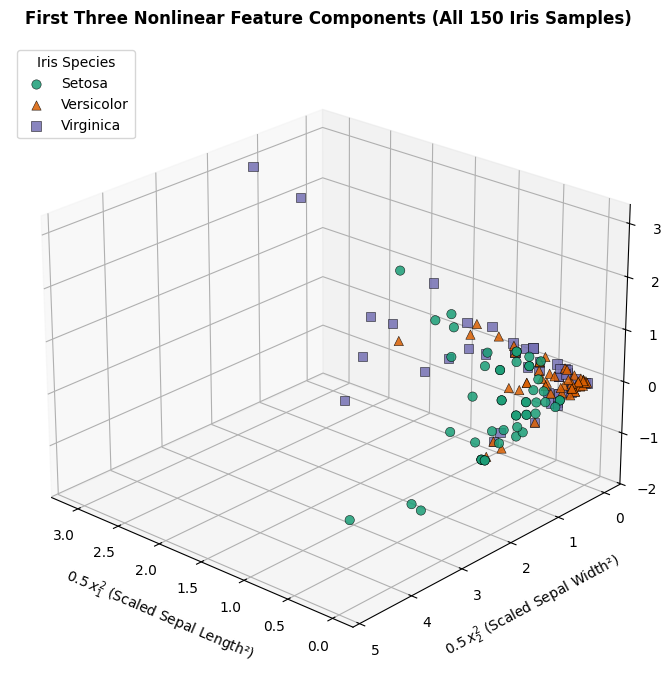

In [12]:
all_samples_6d = map_to_6d_space(sepal_std)

fig_3d = plt.figure(figsize=(9, 7))
ax_3d = fig_3d.add_subplot(111, projection="3d")

palette = ["#1b9e77", "#d95f02", "#7570b3"]
markers = ["o", "^", "s"]

for class_id, class_label in enumerate(species_names):
    mask = (species_idx == class_id)
    ax_3d.scatter(
        all_samples_6d[mask, 0],  # 0.5 * x1^2
        all_samples_6d[mask, 1],  # 0.5 * x2^2
        all_samples_6d[mask, 2],  # (x1 * x2) / sqrt(2)
        c=palette[class_id],
        marker=markers[class_id],
        label=class_label.capitalize(),
        s=45,
        alpha=0.85,
        edgecolors="k",
        linewidth=0.4,
    )

ax_3d.set_title("First Three Nonlinear Feature Components (All 150 Iris Samples)", fontsize=12, fontweight="bold", pad=14)
ax_3d.set_xlabel(r"$0.5\,x_1^2$ (Scaled Sepal Length²)", labelpad=10)
ax_3d.set_ylabel(r"$0.5\,x_2^2$ (Scaled Sepal Width²)", labelpad=10)
ax_3d.set_zlabel(r"$\frac{x_1 x_2}{\sqrt{2}}$ (Interaction Term)", labelpad=10)
ax_3d.legend(title="Iris Species", loc="upper left")
ax_3d.view_init(elev=24, azim=132)

plt.tight_layout()
plt.show()